# Engine Prognostics
## Summary
- **FD001: 17.14 cycles MAE**, compared with 31.05 for the age-only baseline. Selected model: Ridge.
- **FD003: 15.14 cycles MAE**, compared with 38.37 for the age-only baseline. Selected model: Gradient boosting.

Each result uses 100 official test engines from the **NASA C-MAPSS simulated degradation benchmark**. These are benchmark results, not measurements from operational aircraft. Interval coverage is high but intervals are wide; model error and uncertainty are both exposed in the app.

Data: [Kaggle distribution](https://www.kaggle.com/datasets/behrad3d/nasa-cmaps), CC0 as listed by B²; [NASA provenance](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data).

## Context and methods
**Question:** How accurately can current and past sensor observations estimate remaining operating cycles?

FD001 has compressor degradation; FD003 has compressor and fan degradation. Both have one operating condition. Each is modeled independently.

For each dataset, 60 whole training engines fit candidate Ridge and gradient-boosting models. Twenty validation engines, with one seeded random truncation each, select the lower-RMSE candidate. The winner is refitted on those 80 engines. Twenty separate calibration engines supply one truncation each for a nominal 90% split-conformal residual interval. Official test engines are evaluated at their last supplied observation.

Features: cycle count, 14 sensor readings, trailing ten-cycle means and trailing deltas (43 total). Feature calculations never use later cycles. Targets and predictions are capped at 125 cycles; all reported test errors use **uncapped** official truth. The age-only baseline uses median training-engine lifetime minus elapsed cycles, clipped at zero.

### Key assumptions and limitations
Calibration censoring is random, while official test censoring follows the benchmark generation process. Exchangeability is not assured. Early-life RUL may be unidentified from sensor readings, and the 125-cycle cap contributes to underestimation for long-lived engines. The small calibration set produces wide intervals. The two fault scenarios do not test changing operating conditions or transfer to physical engines.

Model candidates and their parameters are fixed in `pipeline.py`. The conformal implementation uses the exact finite-sample order statistic; a unit test guards its rank calculation.

### 1. Reproduce the full experiment

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pipeline import run
plt.rcParams.update({'figure.figsize': (10, 4.6), 'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 14, 'font.size': 11, 'axes.grid': True, 'grid.alpha': .15})
artifact = run()
figures = Path('artifacts/figures')
figures.mkdir(exist_ok=True)


[
  {
    "dataset": "FD001",
    "winner": "Ridge",
    "metrics": {
      "mae": 17.139272218612085,
      "rmse": 22.01526843413665,
      "bias": 1.4541960285034055,
      "n": 100,
      "coverage": 1.0,
      "interval_radius": 84.42185225969524,
      "baseline": {
        "mae": 31.05,
        "rmse": 39.84858843171236,
        "bias": -4.89,
        "n": 100
      },
      "mae_ci95": [
        14.623837050618613,
        19.887074599680258
      ]
    }
  },
  {
    "dataset": "FD003",
    "winner": "Gradient boosting",
    "metrics": {
      "mae": 15.141563006216664,
      "rmse": 20.323565170996623,
      "bias": 4.957395242829671,
      "n": 100,
      "coverage": 1.0,
      "interval_radius": 165.0,
      "baseline": {
        "mae": 38.37,
        "rmse": 48.58116919136467,
        "bias": -2.87,
        "n": 100
      },
      "mae_ci95": [
        12.613509117008714,
        17.782385467421037
      ]
    }
  }
]


### 2. Inspect partitioning and model selection

In [2]:
for result in artifact['results']:
    parts = result['split']
    assert not (set(parts['fit']) & set(parts['validation']) or set(parts['fit']) & set(parts['calibration']) or set(parts['validation']) & set(parts['calibration']))
    print(result['dataset'], {k:len(v) for k,v in parts.items()}, 'winner:', result['winner'])
    display(pd.DataFrame(result['validation_scores']))

FD001 {'fit': 60, 'validation': 20, 'calibration': 20} winner: Ridge


,model,mae,rmse,bias,n
0,Ridge,25.231576,32.822845,-11.980109,20
1,Gradient boosting,25.691447,32.831987,-13.647493,20


FD003 {'fit': 60, 'validation': 20, 'calibration': 20} winner: Gradient boosting


,model,mae,rmse,bias,n
0,Ridge,34.430536,50.936332,-22.023852,20
1,Gradient boosting,33.335627,50.203707,-21.240243,20


## Results
### Baseline comparison on official test engines

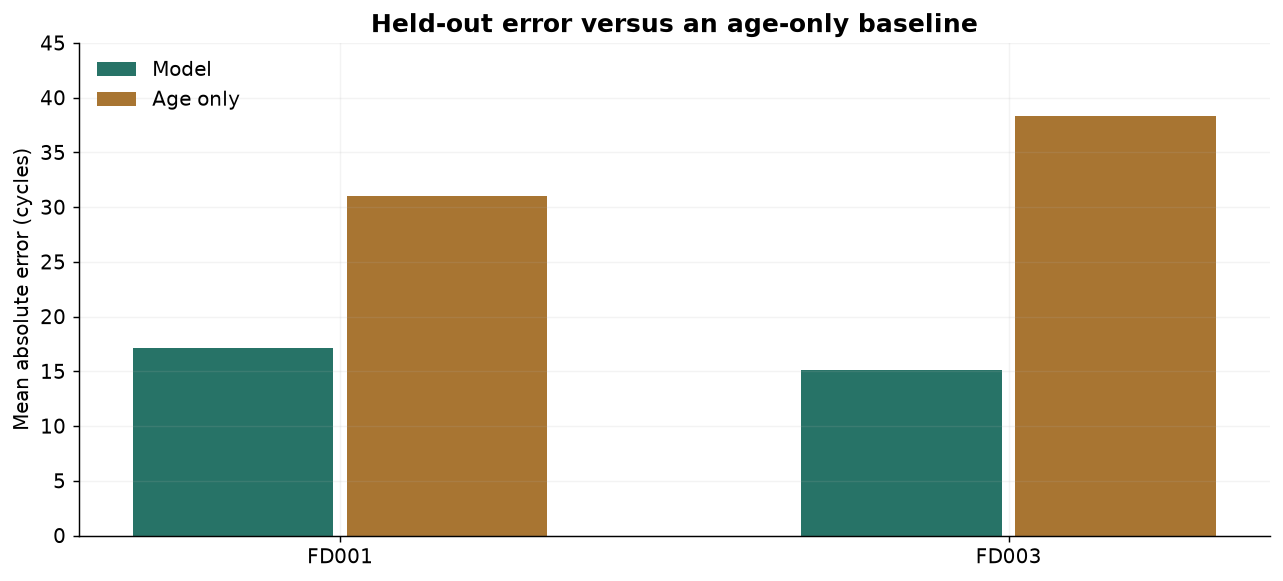

,dataset,method,MAE,RMSE
0,FD001,Model,17.139272,22.015268
1,FD001,Age only,31.050000,39.848588
2,FD003,Model,15.141563,20.323565
3,FD003,Age only,38.370000,48.581169


In [3]:
scores = []
for result in artifact['results']:
    m = result['metrics']
    scores.extend([{'dataset':result['dataset'],'method':'Model','MAE':m['mae'],'RMSE':m['rmse']}, {'dataset':result['dataset'],'method':'Age only','MAE':m['baseline']['mae'],'RMSE':m['baseline']['rmse']}])
scores = pd.DataFrame(scores)
fig, ax = plt.subplots()
for i, method in enumerate(['Model','Age only']):
    selected = scores[scores.method==method]
    ax.bar(np.arange(2)+(i-.5)*.32, selected.MAE, width=.3, color=['#277367','#a87532'][i], label=method)
ax.set(xticks=[0,1],xticklabels=['FD001','FD003'],ylabel='Mean absolute error (cycles)',title='Held-out error versus an age-only baseline',ylim=(0,45))
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(figures/'baseline.png'); plt.show()
display(scores)

### Where the model misses

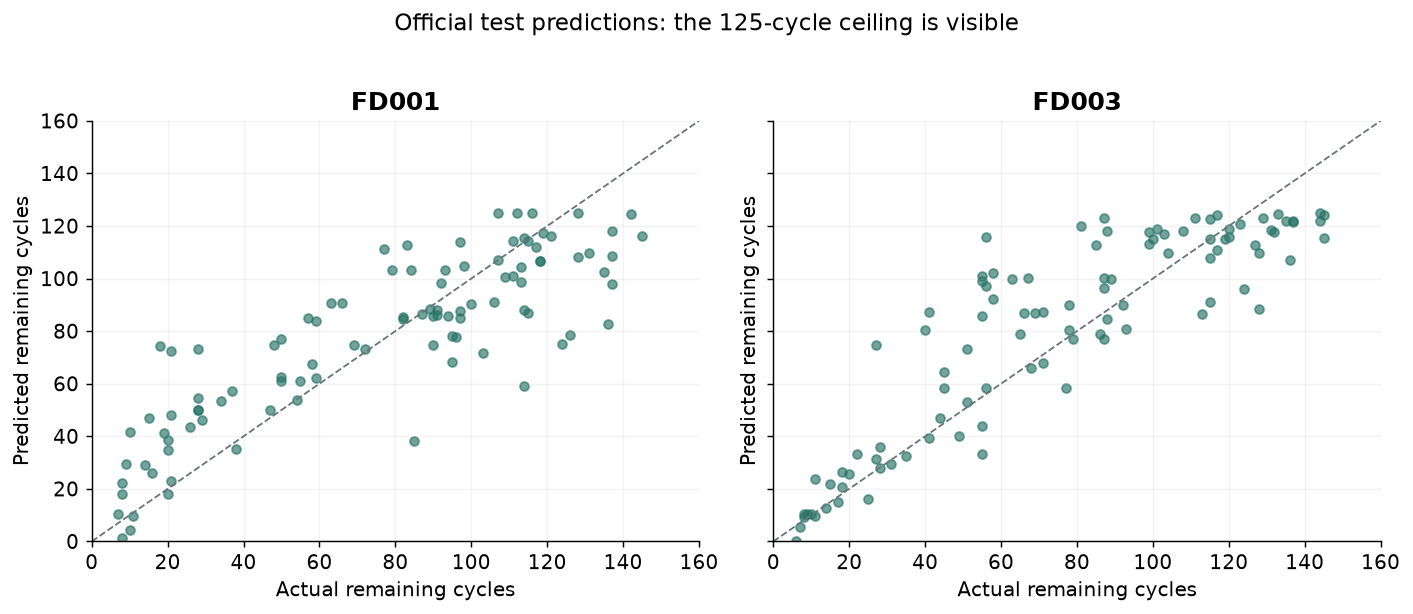

In [4]:
fig, axes = plt.subplots(1,2,figsize=(11,4.6),sharex=True,sharey=True)
for ax,result in zip(axes,artifact['results']):
    frame = pd.DataFrame(result['engines'])
    ax.scatter(frame.actual,frame.predicted,s=24,alpha=.65,color='#277367')
    ax.plot([0,160],[0,160],ls='--',color='#687478',lw=1,label='Perfect prediction')
    ax.set(title=result['dataset'],xlabel='Actual remaining cycles',ylabel='Predicted remaining cycles',xlim=(0,160),ylim=(0,160))
fig.suptitle('Official test predictions: the 125-cycle ceiling is visible',fontsize=13,y=1.02)
fig.tight_layout(); fig.savefig(figures/'prediction-errors.png',bbox_inches='tight'); plt.show()

The ceiling is a deliberate modeling choice, not a plotting limit. A score alone hides the underestimation of engines with actual RUL above that ceiling.

### Uncertainty is not the same as precision

,Dataset,Nominal coverage,Test coverage,Mean interval width (cycles),MAE 95% bootstrap lower,MAE 95% bootstrap upper
0,FD001,0.9,1.0,152.22860,14.623837,19.887075
1,FD003,0.9,1.0,245.27737,12.613509,17.782385


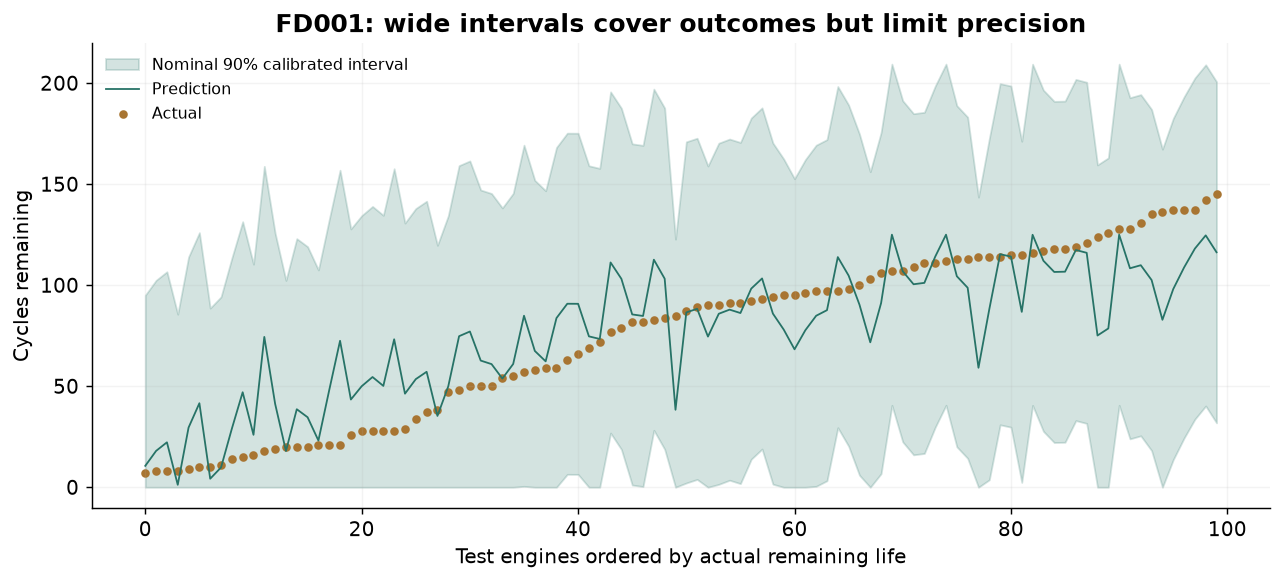

In [5]:
interval_rows=[]
for result in artifact['results']:
    m=result['metrics']; f=pd.DataFrame(result['engines'])
    interval_rows.append({'Dataset':result['dataset'],'Nominal coverage':.90,'Test coverage':m['coverage'],'Mean interval width (cycles)':float((f.upper-f.lower).mean()),'MAE 95% bootstrap lower':m['mae_ci95'][0],'MAE 95% bootstrap upper':m['mae_ci95'][1]})
display(pd.DataFrame(interval_rows))
result=artifact['results'][0]; frame=pd.DataFrame(result['engines']).sort_values('actual').reset_index(drop=True)
fig,ax=plt.subplots()
ax.fill_between(frame.index,frame.lower,frame.upper,alpha=.2,color='#277367',label='Nominal 90% calibrated interval')
ax.plot(frame.index,frame.predicted,color='#277367',lw=1,label='Prediction')
ax.scatter(frame.index,frame.actual,color='#a87532',s=14,label='Actual')
ax.set(title='FD001: wide intervals cover outcomes but limit precision',xlabel='Test engines ordered by actual remaining life',ylabel='Cycles remaining')
ax.legend(frameon=False,fontsize=9); fig.tight_layout(); fig.savefig(figures/'uncertainty.png'); plt.show()

MAE intervals bootstrap the 100 independent test-engine errors 2,000 times. They describe uncertainty in average error, whereas the calibrated prediction intervals concern an individual engine. Those are different quantities.

### Replay a long observed trajectory

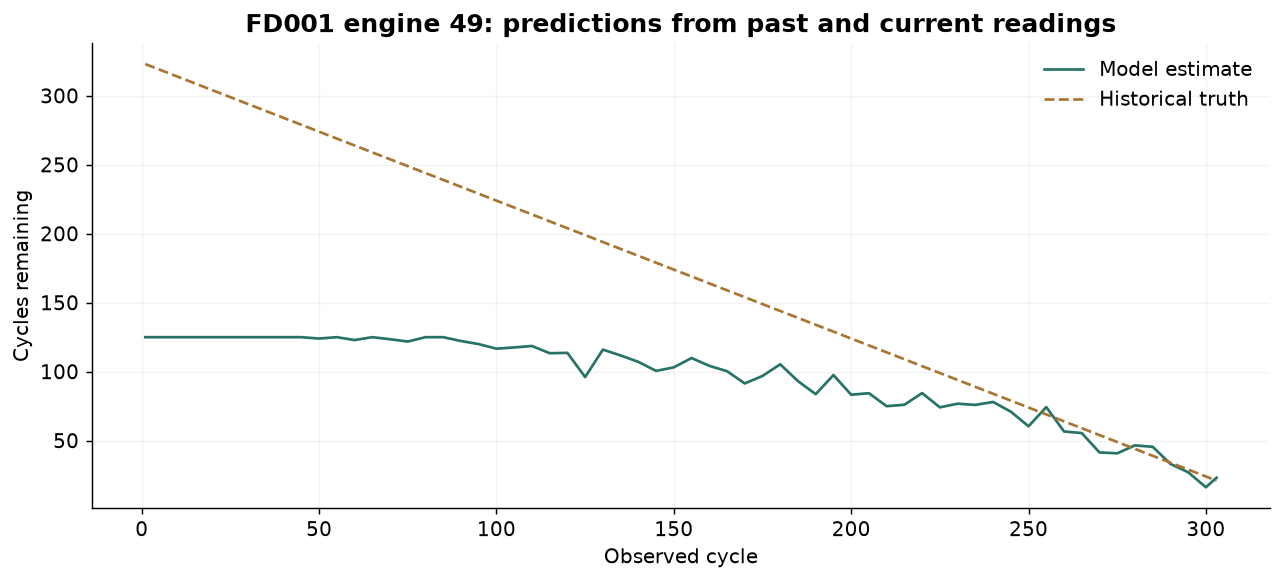

In [6]:
result=artifact['results'][0]
engine=max(result['engines'],key=lambda r:r['last_cycle'])['engine']
history=pd.DataFrame(result['history']); history=history[history.engine==engine]
fig,ax=plt.subplots()
ax.plot(history.cycle,history.predicted,label='Model estimate',color='#277367')
ax.plot(history.cycle,history.actual,label='Historical truth',color='#a87532',ls='--')
ax.set(title=f'FD001 engine {engine}: predictions from past and current readings',xlabel='Observed cycle',ylabel='Cycles remaining')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(figures/'replay.png'); plt.show()

The default example is chosen for the longest observed trajectory, not as a representative error estimate. Every official test engine is available in the interactive app. Display traces are sampled every five cycles plus endpoints; model fitting and scoring use the full records.

## Takeaways
The sensor models outperform a transparent age-only baseline in both scenarios. Their limitations are substantial: early-life ambiguity, capped forecasts, broad intervals, and simulated rather than operational data. A further research iteration should add FD002/FD004 operating-condition variation, evaluate more engine-level folds, and assess calibration under matched censoring before considering any real-world use.